# Figure 7 — Phase 4 reproduction and β ablation (100,000 steps)

Run the **three plotting cells in order** from `paper3-beta-vae/` or `paper3-beta-vae/notebooks/`. Uses the official local dSprites archive and **four genuinely trained seed-42, 100,000-step checkpoints** in `results/phase4/step100000/beta{1,2,3,4}/model.pt`. All figures render **inline**; there is no training, download, or figure export. The dataset loader may create its normal image cache.

**Phase boundary:** The original independent **Phase 3** reproduction remains `notebooks/reproduce_figure7.ipynb` using 30,000-step β = 4 / β = 1 models under `results/seed42/`. The present notebook is a **Phase 4 diagnostic**: β = 1 and 4 continued to 100k; β = 2 and 3 trained independently from initialization to 100k. β = 2 and 3 **are not substitutes** for the original β = 4 Figure 7A.

Encoder-response limits are shared across all four models. Latent selection is based on posterior variance, never handpicked semantic assignments. The descriptive factor-response fractions are *not* the formal Higgins disentanglement metric.

## Figure 7A — β-VAE (β = 4), Phase 4 at 100k

Calculates position, scale, and rotation responses from the complete dSprites dataset and shows five decoder traversals per latent, using the same plotting code and reference image as Phase 3. The β = 1, 2, and 3 models are also evaluated here to establish common plot limits.

Project: C:\Users\ASUS\Documents\GitHub\advanced-ml-paper-reproductions\paper3-beta-vae | Device: cpu | Eval batch: 512
Evaluating beta=4, seed=42, step=100000 ...
Evaluating beta=1, seed=42, step=100000 ...
Evaluating beta=2, seed=42, step=100000 ...
Evaluating beta=3, seed=42, step=100000 ...


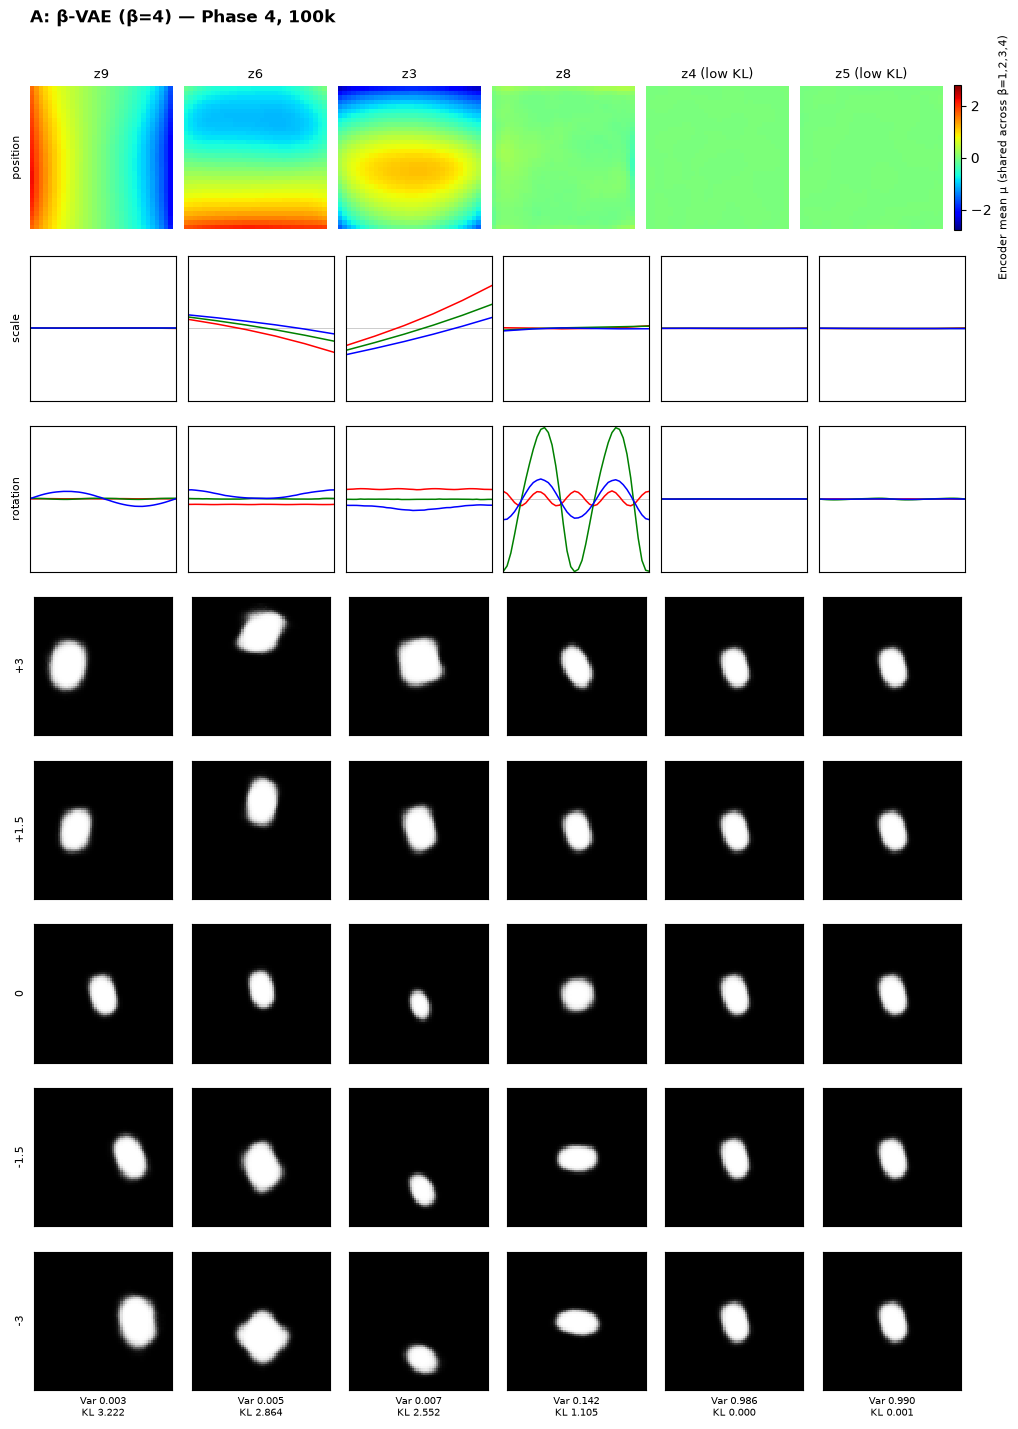

β=4 | 100,000 steps | BCE/image=80.768 | KL/image=9.742 | active (KL>0.1)=4 | latent columns=[9, 6, 3, 8, 4, 5]


In [2]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline

_here = Path.cwd().resolve()
PROJECT = next((p for p in (_here, _here.parent) if (p / 'src' / 'visualize.py').is_file()), None)
if PROJECT is None:
    raise FileNotFoundError('Start this notebook from paper3-beta-vae/ or its notebooks/ folder.')
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))

from src.data import DSprites
from src.visualize import data_for_panel, shared_limits, draw_panel

DATA = PROJECT / 'data' / 'dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz'
RUNS = PROJECT / 'results' / 'phase4' / 'step100000'
CHECKPOINTS = {beta: RUNS / f'beta{beta}' / 'model.pt' for beta in (1, 2, 3, 4)}
for path in (DATA, *CHECKPOINTS.values()):
    if not path.is_file():
        raise FileNotFoundError(f'Missing required input: {path}')
for path in CHECKPOINTS.values():
    if path.stat().st_size < 1_000_000:
        raise RuntimeError(f'{path} looks like a Git LFS pointer, not model weights. Run git lfs pull.')

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
EVAL_BATCH_SIZE = 2048 if DEVICE.type == 'cuda' else 512
print(f'Project: {PROJECT} | Device: {DEVICE} | Eval batch: {EVAL_BATCH_SIZE}')

ds = DSprites(DATA)
PANELS = {}
for beta in (4, 1, 2, 3):
    print(f'Evaluating beta={beta}, seed=42, step=100000 ...', flush=True)
    panel = data_for_panel(CHECKPOINTS[beta], ds, DEVICE, EVAL_BATCH_SIZE)
    meta = panel['meta']
    assert float(meta['beta']) == beta, (beta, meta['beta'])
    assert int(meta['seed']) == 42 and int(meta['step']) == 100000, (beta, meta)
    PANELS[beta] = panel
LIMITS = shared_limits(list(PANELS.values()))

def show_panel(beta, heading):
    panel = PANELS[beta]
    fig, axes = plt.subplots(8, 6, figsize=(11, 15),
        gridspec_kw={'height_ratios': [1.05, 1.05, 1.05, 1, 1, 1, 1, 1]})
    im = draw_panel(panel, axes, 'A' if beta != 1 else 'B', LIMITS)
    # The original drawing helper embeds an A/B heading; label our Phase 4 arm explicitly.
    for annotation in axes[0, 0].texts:
        annotation.set_text(heading)
    fig.subplots_adjust(wspace=.08, hspace=.18, left=.08, right=.93, top=.95, bottom=.08)
    cb = fig.colorbar(im, ax=list(axes[0]), fraction=.012, pad=.012)
    cb.set_label('Encoder mean μ (shared across β=1,2,3,4)', fontsize=8)
    display(fig)
    plt.close(fig)
    diag = panel['diagnostics']
    kl = np.asarray(panel['factors']['kl_per_latent'])
    print(f'β={beta} | 100,000 steps | BCE/image={diag["bce_per_image"]:.3f} | '
          f'KL/image={diag["kl_per_image"]:.3f} | active (KL>0.1)={(kl > 0.1).sum()} | '
          f'latent columns={[i+1 for i in panel["selected"]]}')

show_panel(4, 'A: β-VAE (β=4) — Phase 4, 100k')

## Figure 7B — Standard VAE (β = 1), Phase 4 at 100k

Uses the same architecture, seed, dataset, number of optimizer steps, reference image, and shared response scales as Figure 7A. Only β differs. The checkpoint was continued from the independent 30k Phase 3 model.

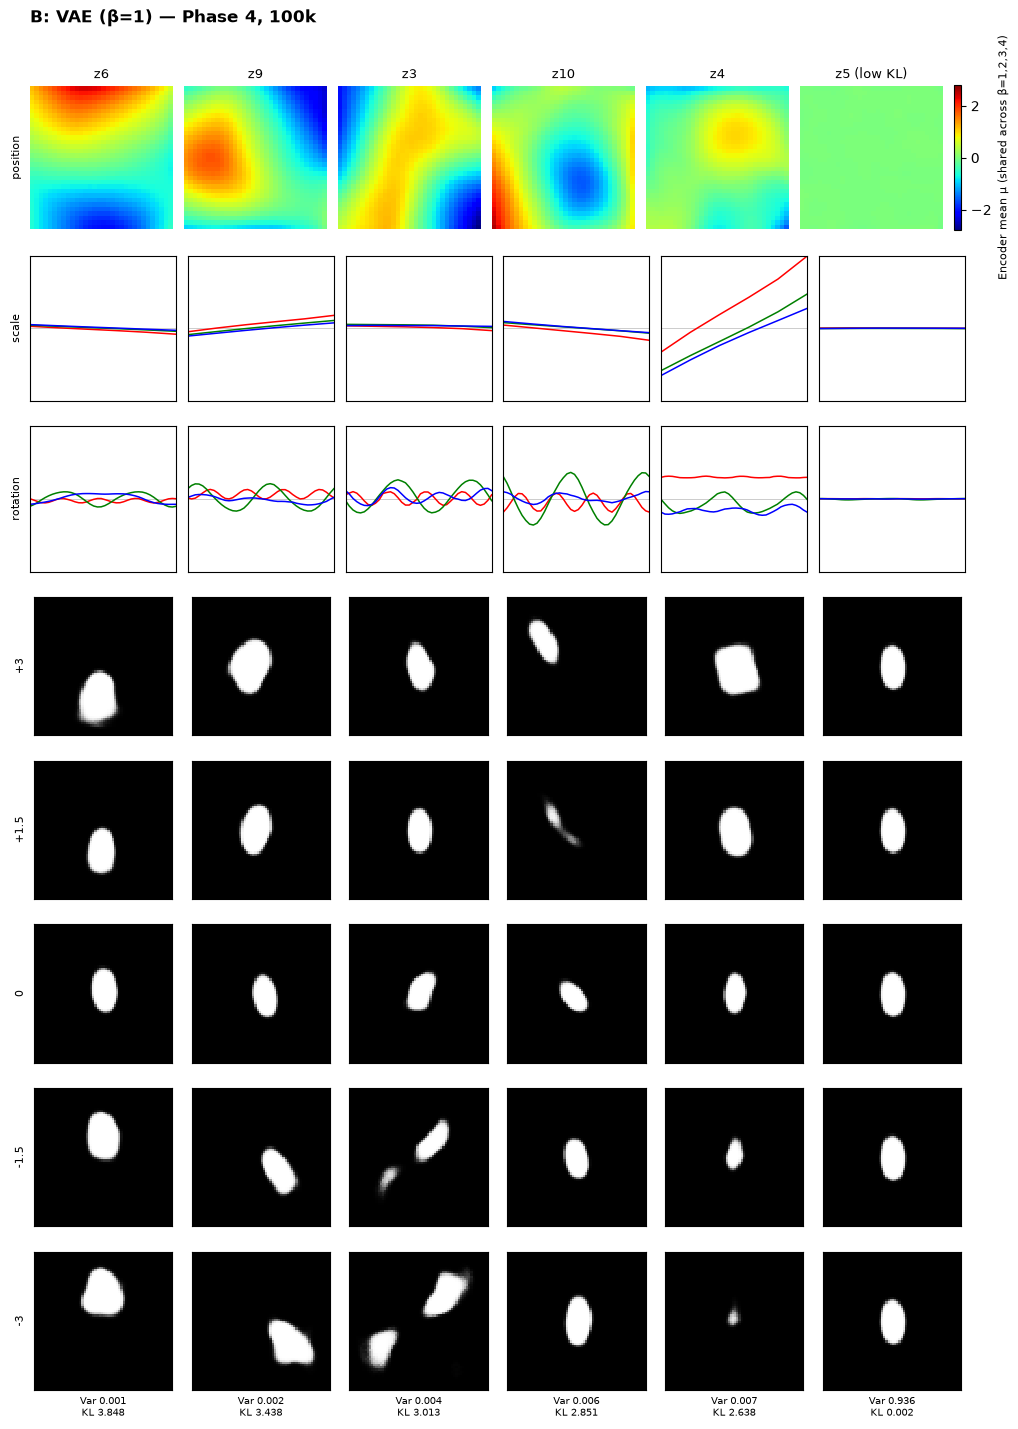

β=1 | 100,000 steps | BCE/image=43.396 | KL/image=18.313 | active (KL>0.1)=6 | latent columns=[6, 9, 3, 10, 4, 5]


In [3]:
show_panel(1, 'B: VAE (β=1) — Phase 4, 100k')

## Phase 4 diagnostic — Intermediate β = 2 and β = 3

These are **additional models**, each trained from scratch with seed 42 to 100,000 steps using the same fully connected architecture, Adagrad (LR 0.01), and batch size 256. Unlike the original Figure 7 comparison, they test whether reducing the KL weight allows scale to become a more independently represented factor. Both render with the identical global plot limits as β = 1 and 4. The table computes diagnostics from the checkpoints; it does not insert published or previously recorded values.

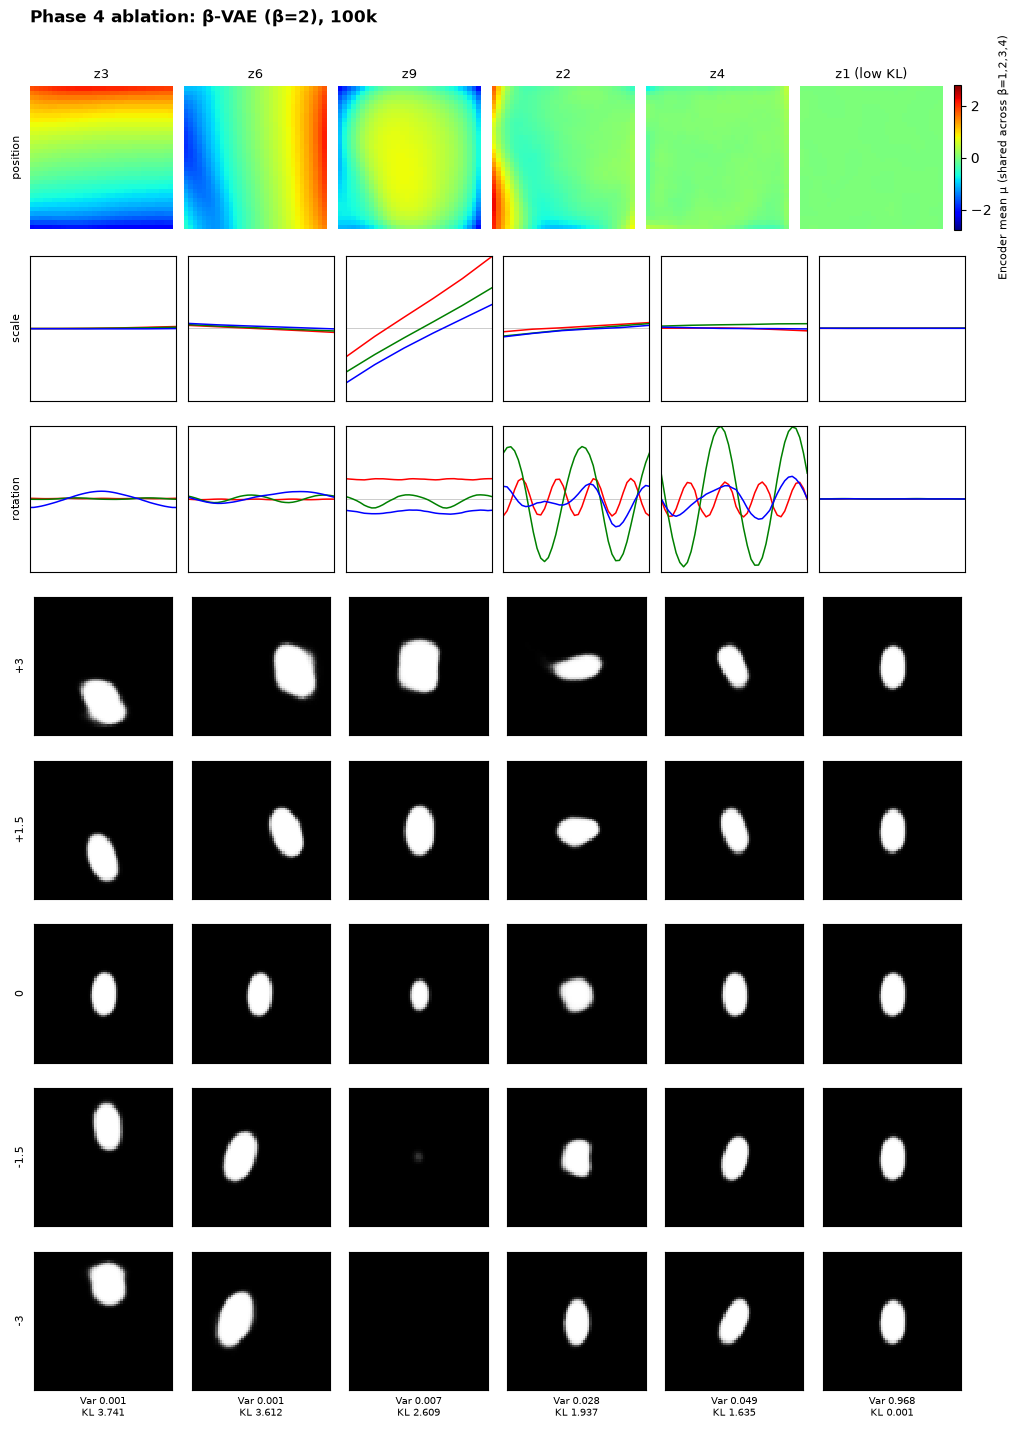

β=2 | 100,000 steps | BCE/image=53.315 | KL/image=13.561 | active (KL>0.1)=5 | latent columns=[3, 6, 9, 2, 4, 1]


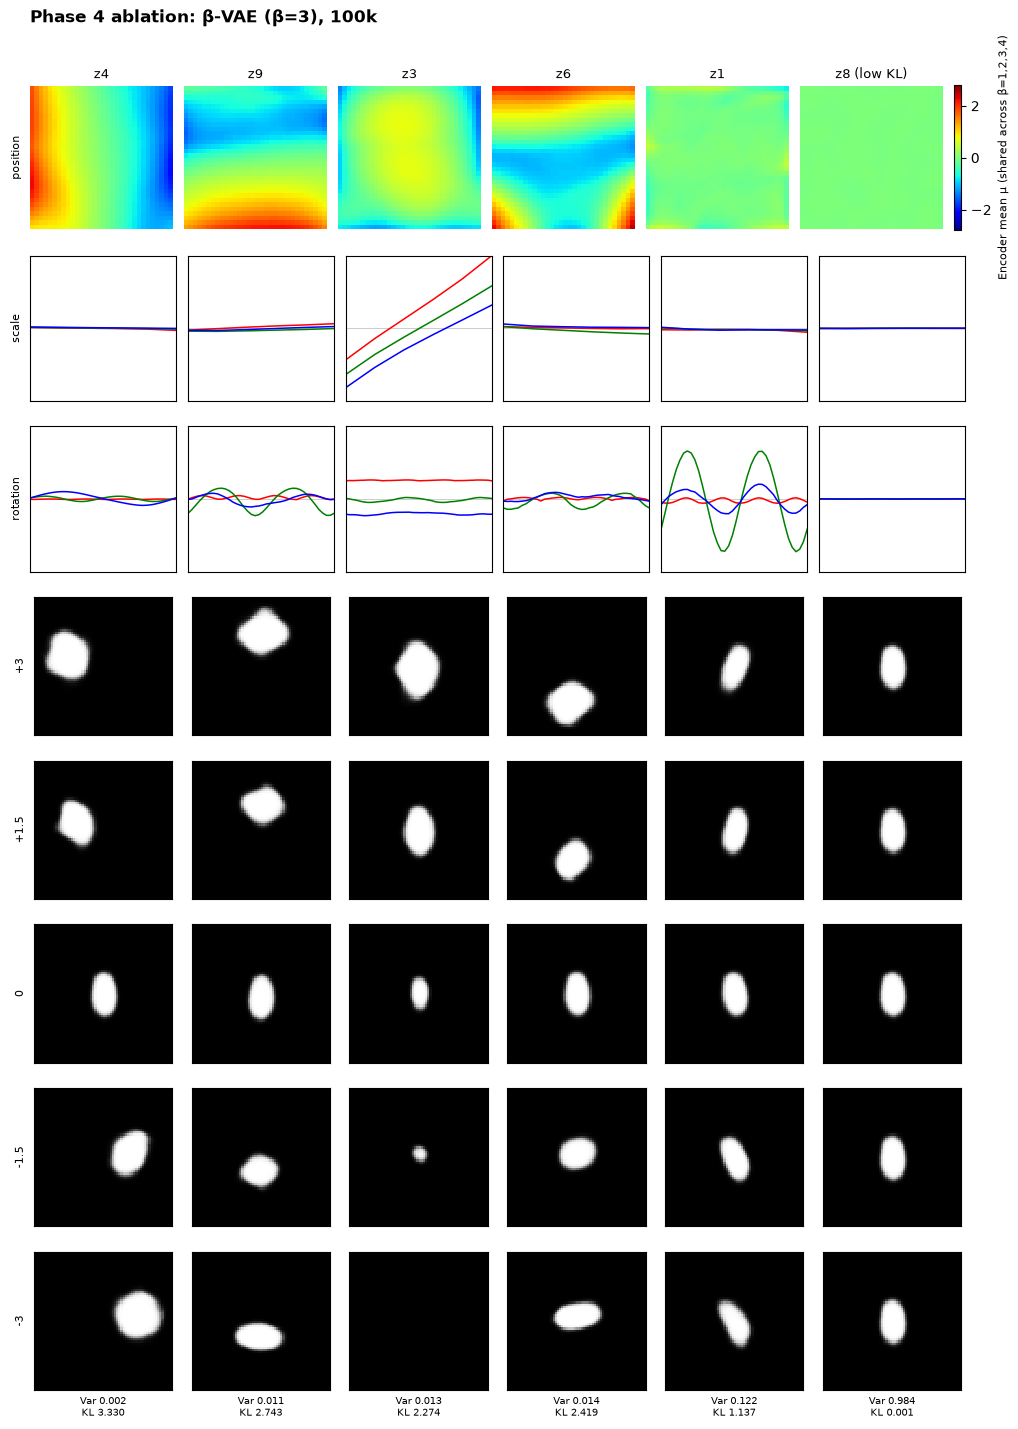

β=3 | 100,000 steps | BCE/image=65.427 | KL/image=11.902 | active (KL>0.1)=5 | latent columns=[4, 9, 3, 6, 1, 8]


,β,Steps,BCE/image,Total KL,Active latents (KL>0.1),Best active scale latent,Scale response fraction
0,1,100000,43.396,18.317,6,z4,0.738
1,2,100000,53.315,13.541,5,z9,0.592
2,3,100000,65.427,11.906,5,z3,0.698
3,4,100000,80.768,9.745,4,z3,0.176


Scale-response fractions are descriptive conditional-mean ratios, NOT the paper’s formal score.
β=2/3 are Phase 4 ablations and must not be relabeled as the original β=4 Figure 7A.


In [4]:
show_panel(2, 'Phase 4 ablation: β-VAE (β=2), 100k')
show_panel(3, 'Phase 4 ablation: β-VAE (β=3), 100k')

rows = []
for beta in (1, 2, 3, 4):
    p = PANELS[beta]
    kls = np.asarray(p['factors']['kl_per_latent'])
    frac = p['factor_diagnostics']['within_4_factor_signal_fractions']
    scale = np.asarray(frac['scale'])
    eligible = np.flatnonzero(kls > 0.1)
    best = int(eligible[np.argmax(scale[eligible])]) if len(eligible) else int(np.argmax(scale))
    rows.append({
        'β': beta,
        'Steps': int(p['meta']['step']),
        'BCE/image': round(float(p['diagnostics']['bce_per_image']), 3),
        'Total KL': round(float(kls.sum()), 3),
        'Active latents (KL>0.1)': int(len(eligible)),
        'Best active scale latent': f'z{best+1}',
        'Scale response fraction': round(float(scale[best]), 3),
    })
display(pd.DataFrame(rows).sort_values('β').reset_index(drop=True))
print('Scale-response fractions are descriptive conditional-mean ratios, NOT the paper’s formal score.')
print('β=2/3 are Phase 4 ablations and must not be relabeled as the original β=4 Figure 7A.')